In [1]:
import numpy as np
import scipy

import matplotlib.pyplot as plt
import seaborn as sns

from tqdm import tqdm

import tifffile
import fastplotlib as fpl

To silence this warning, use a fully namespaced name.
To silence this warning, use a fully namespaced name.
To silence this warning, use a fully namespaced name.
To silence this warning, use a fully namespaced name.
To silence this warning, use a fully namespaced name.
To silence this warning, use a fully namespaced name.


Image(value=b'\x89PNG\r\n\x1a\n\x00\x00\x00\rIHDR\x00\x00\x01,\x00\x00\x007\x08\x06\x00\x00\x00\xb6\x1bw\x99\x…

Unable to find extension: VK_EXT_swapchain_colorspace


Available devices:
✅ (default) | AMD RADV POLARIS10 (ACO) | DiscreteGPU | Vulkan | Mesa 20.3.5 (ACO)
❗ | llvmpipe (LLVM 11.0.1, 256 bits) | CPU | Vulkan | Mesa 20.3.5 (LLVM 11.0.1)
✅ | NVIDIA GeForce RTX 3080 | DiscreteGPU | Vulkan | 530.30.02
❗ | Radeon RX 570 Series (POLARIS10, DRM 3.40.0, 5.10.0-21-amd64, LLVM 11.0.1) | Unknown | OpenGL | 


In [2]:
%matplotlib inline

In [ ]:
path = "/mnt/home/kkolar/data/jason/jason/M19/D05/M19D5_MC.tif"
movie = tifffile.imread(path)[:10_000, 128:-138:2, 138:-132:2].astype(np.float32)

In [ ]:
movie_mean = movie.mean(axis=0)

In [ ]:
iw_movie = fpl.ImageWidget(movie, cmap="gnuplot2")
iw_movie.show()

In [8]:
iw_movie.window_funcs = {"t": (np.mean, 33)}

In [3]:
v1 = np.load("./v_ss-2.npy")

In [4]:
N_ROWS, N_COLS = 123, 121
n_pixels = N_ROWS * N_COLS
B = v1[0].reshape(n_pixels, n_pixels)
B = np.abs((B + B.T) / 2)

B.shape

(14883, 14883)

RFBOutputContext()

/home/kushal/repos/fastplotlib/fastplotlib/graphics/_features/_base.py:21: UserWarning: casting float64 array to float32
  warn(f"casting {array.dtype} array to float32")


JupyterWgpuCanvas()
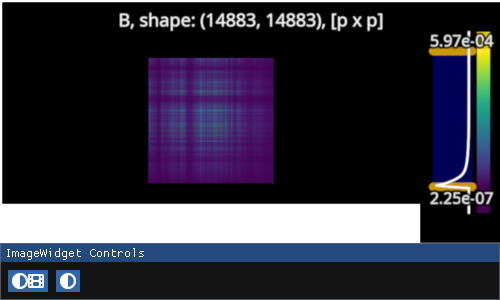

In [5]:
iw_adj = fpl.ImageWidget(
    B, 
    cmap="viridis",
    names=[f"B, shape: {B.shape}, [p x p]"],
)
iw_adj.show()

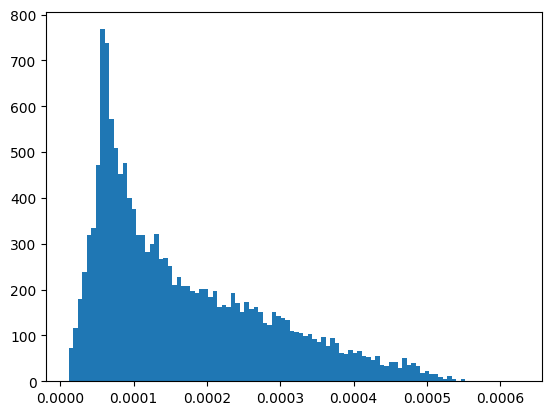

In [6]:
plt.hist(B.max(axis=1), bins=100)
plt.show()

# Determine columns/rowns which are just noise and exclude them

In [7]:
np.argsort(B.sum(axis=0))

array([14766, 14767, 14768, ...,  8792,  8192,  8794])

In [8]:
np.sum(B[14766, :])

np.float64(0.04641665180489722)

In [9]:
np.sum(B[8794, :])

np.float64(2.5013944978859315)

### background image, each pixel's value in the `bg_image` is the sum of that pixel's row/column from `B`

RFBOutputContext()

JupyterWgpuCanvas(css_height='700px', css_width='700px')
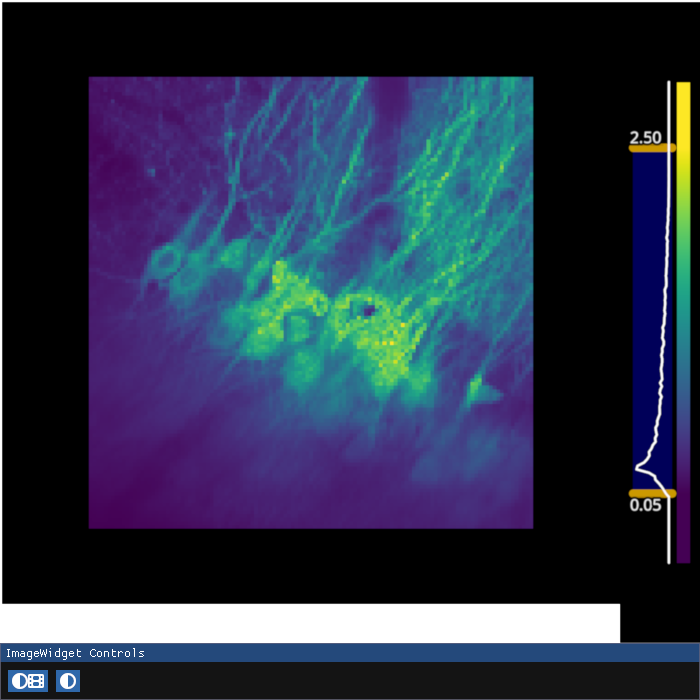

In [10]:
bg_image = B.sum(axis=0).reshape(N_ROWS, N_COLS)
iw_bg = fpl.ImageWidget(bg_image, cmap="viridis", figure_kwargs={"size": (700, 700)})
iw_bg.show()

## bg threshold

In [11]:
bg_threshold = 0.6
iw_bg.managed_graphics[0].vmin = 0.6

In [12]:
bg_ixs = B.sum(axis=0) < bg_threshold
bg_ixs

array([ True,  True,  True, ...,  True,  True,  True])

Used for mapping indices after bg removal back to original pixels in the image

In [13]:
NEW_IXS = np.where(B.sum(axis=0) > bg_threshold)[0]
NEW_IXS

array([   40,    51,    53, ..., 13051, 13052, 13171])

Number of bg pixels

In [14]:
np.count_nonzero(bg_ixs)

8215

# `B` without the bg rows and cols

In [15]:
B2 = B[~bg_ixs][:, ~bg_ixs]
B2.shape

(6668, 6668)

## Eigendecomposition 

In [16]:
K_eig = 30

In [17]:
evals, Qk = scipy.sparse.linalg.eigsh(B2, k=K_eig)

In [18]:
Qk.shape

(6668, 30)

In [19]:
K_interp = 30

In [20]:
max_k, seed_ixs, proj = scipy.linalg.interpolative.interp_decomp(Qk.T[:K_interp], eps_or_k=0.001)
max_k

30

In [21]:
seed_ixs

array([5260, 6302, 4652, ..., 6665, 6666, 6667], dtype=int32)

In [22]:
def coors_from_indices(indices: np.ndarray[int], k) -> np.ndarray:
    """get (x, y) image coordinates from the top `k` given flat pixel `indices`"""
    _ixs = NEW_IXS[indices[:k]]
    ys = np.floor_divide(_ixs, N_ROWS)
    xs = np.mod(_ixs, N_COLS)
    return np.column_stack([xs, ys])

In [23]:
seed_coors = coors_from_indices(seed_ixs, k=50)

RFBOutputContext()

/home/kushal/repos/fastplotlib/fastplotlib/graphics/_features/_base.py:21: UserWarning: casting int64 array to float32
  warn(f"casting {array.dtype} array to float32")


JupyterWgpuCanvas()
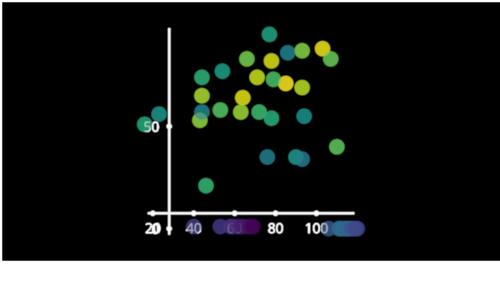

In [24]:
fig_seeds = fpl.Figure()

fig_seeds[0, 0].add_scatter(seed_coors, sizes=15, cmap="viridis_r", alpha=0.7)

fig_seeds.show()

In [25]:
proj.shape

(30, 6638)

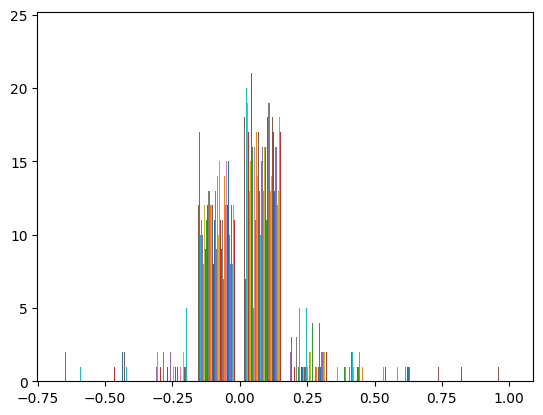

In [26]:
plt.hist(proj[:, :1000])
plt.show()

# Threshold projection

In [27]:
proj_thres = proj.copy()
proj_thres[(proj_thres > -0.5) & (proj_thres < 0.5)] = 0

# reconstruct images from proj

In [28]:
def images_from_proj(projection, k, new_indices, projection_indices):
    """
    reconstruct images that represent each cluster from the interpolative decomposition projection

    Parameters
    ----------
    projection: np.ndarray
        projection
        
    k: int
        number of seeds that exist, this MUST hold: (k + projection.shape[1] = Qk.shape[0])

    new_indices: np.ndarray[int]
        indices that map from smaller-B matrix after thresholding to actual pixel indices in the original big B matrix

    projection_indices: np.ndarray[int]
        indices returned from interp decomp
    """
    images = np.zeros((k, N_ROWS * N_COLS))
    
    projection = np.hstack([np.eye(k), projection])

    indices = new_indices[projection_indices]

    for i in range(k):
        images[i, indices] = projection[i]

    return images.reshape((k, N_ROWS, N_COLS))

In [29]:
proj_images = images_from_proj(
    proj_thres, 
    k=30, 
    new_indices=NEW_IXS, 
    projection_indices=seed_ixs
)

RFBOutputContext()

JupyterWgpuCanvas(css_height='1500px', css_width='1800px')
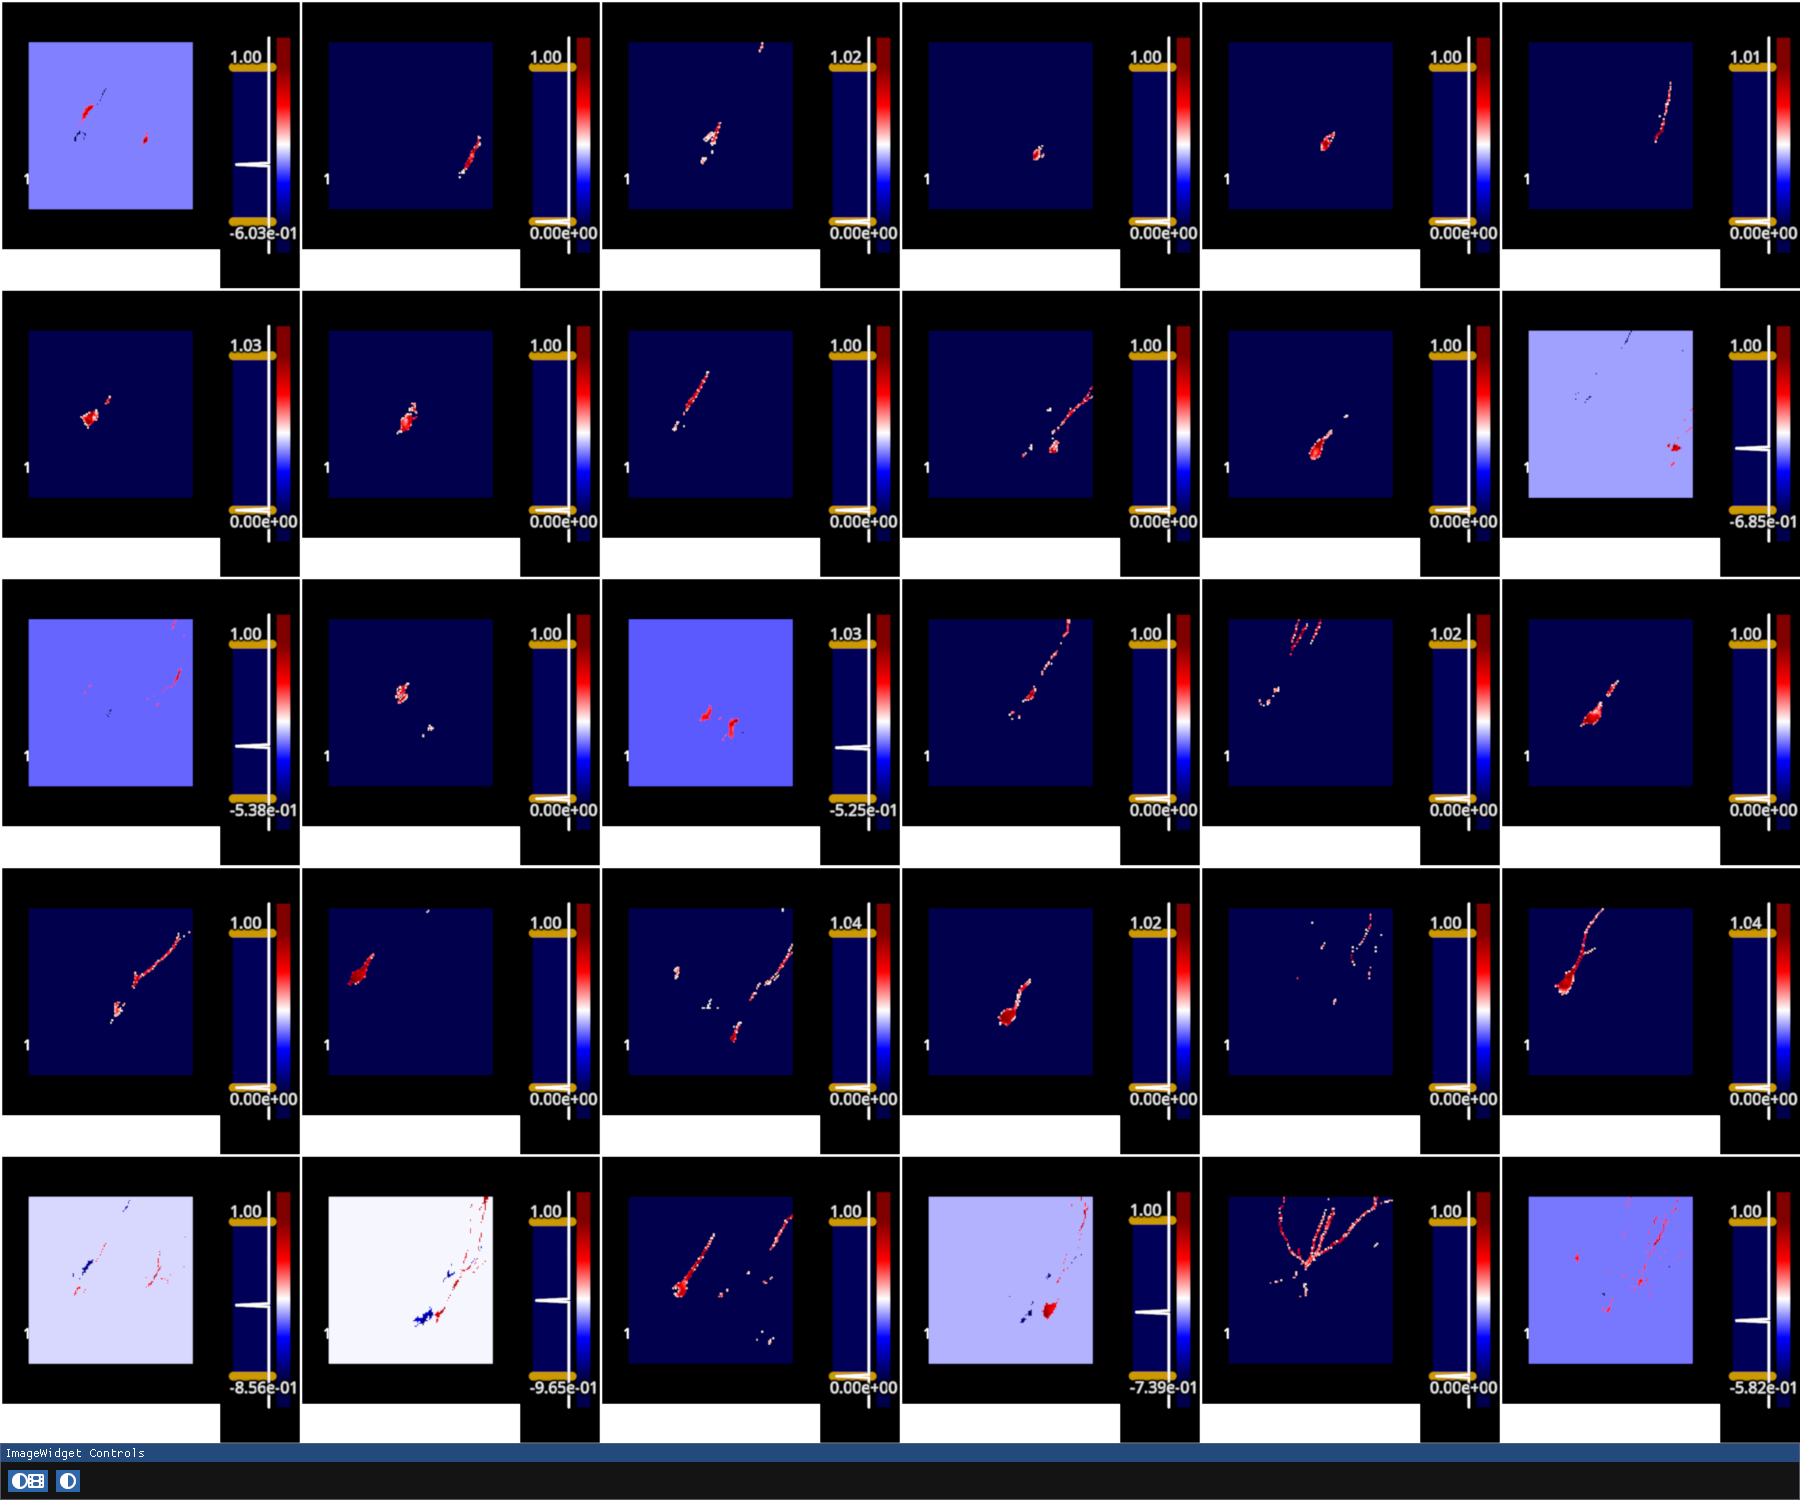

In [30]:
iw_proj_images = fpl.ImageWidget(
    [p for p in proj_images[:30]], 
    cmap="seismic",
    figure_kwargs={"size": (1800, 1500)},
)
iw_proj_images.show()

RFBOutputContext()

JupyterWgpuCanvas()
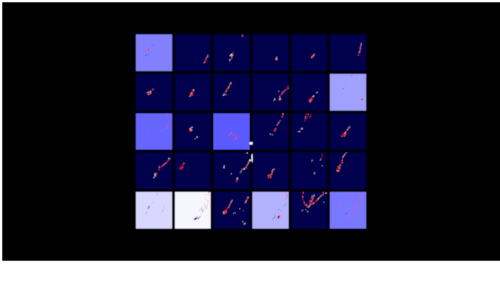

In [34]:
fig = fpl.Figure()

i = 0
for col_ix in range(5):
    for row_ix in range(6):
        img = proj_images[i]
        fig[0, 0].add_image(img, cmap="seismic", offset=(row_ix * (img.shape[1] + 10), col_ix * (img.shape[0] + 10), 0))
        i += 1

fig.show()


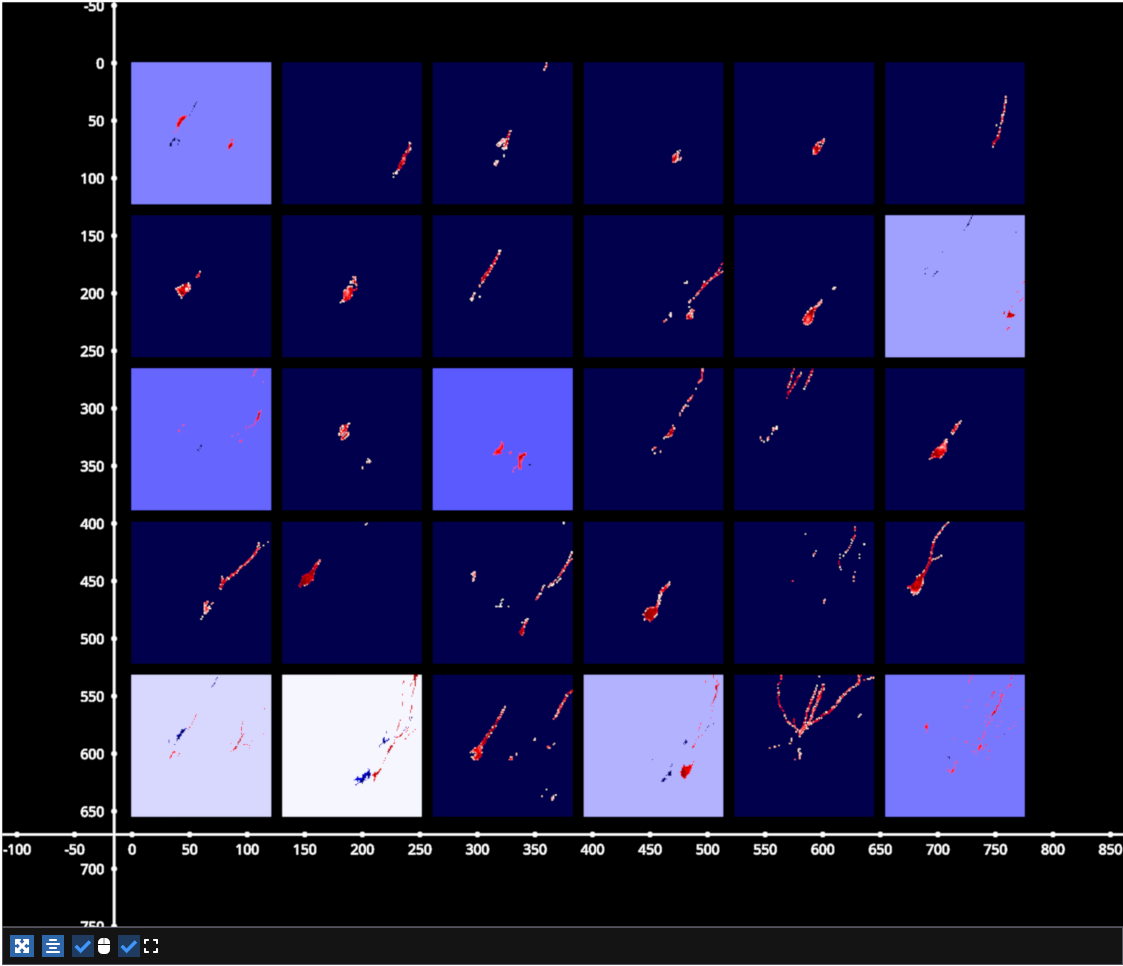

In [35]:
fig.canvas.snapshot()